In [1]:
import pandas as pd
import math
from sys import float_info
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro, wilcoxon, ttest_rel, pearsonr
from numpy import std
import numpy as np
#TODO fix Gopstein17b

In [2]:
def lk_to_dict(lk): 
    lk_arr = lk.strip("[]").split("], [")
    dict = {}
    for l in lk_arr: 
        key, val = l.split(", ")
        dict[int(key)] = float(val)
    return(dict)
def loss_from_df(df): 
    correct_labels = df["correct"]
    answer = df["answer"]
    likelihoods = df["likelihoods"]
    eval_loss = 0
    count = 0
    curr_iter = -1
    prob = 1
    losses = []
    tokens = []
    curr_tokens = []
    for label, iter, lk in zip(correct_labels, answer, likelihoods):  
        lbl, atkn = label.strip("[]").split(",")
        lk_dict = lk_to_dict(lk)
        if curr_iter == -1: 
            curr_iter = iter
        if curr_iter == iter : 
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob *= p
            curr_tokens.append([lbl, atkn])
        else: 
            if prob == 0: 
                    eval_loss += -math.log(float_info.min)
                    losses.append(-math.log(float_info.min))
            else:
                    eval_loss += -math.log(prob)
                    losses.append(-math.log(prob))
            tokens.append(curr_tokens)
            curr_tokens = [[lbl, atkn]]
            count += 1
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob = p
            curr_iter = iter
    if prob == 0: 
        eval_loss += -math.log(float_info.min)
        losses.append(-math.log(float_info.min))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    elif prob != 1:
        eval_loss += -math.log(prob)
        losses.append(-math.log(prob))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    count += 1
    tokens.append(curr_tokens)
    curr_tokens = []
    return(losses, tokens)


In [3]:
def get_values(study, model, variant = "no_order_no_desc"): 
    answer_amounts = pd.read_csv(f"answer_amounts/{study}.csv")
    result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
    amount_sum = 0
    for i in range(len(answer_amounts)):
        task = answer_amounts["task"].iloc[i]
        answer = answer_amounts["answer"].iloc[i]
        amount = answer_amounts["amount"].iloc[i]
        answer_num = answer_amounts["answer_num"].iloc[i]
        if study == "Gopstein17b" and (task == "task_g" or task == "task_h"):
            continue 
        answer_df = pd.read_csv(f"full_results/{model}/{study}_{variant}/{study}_{variant}_{task}_{answer_num}.csv")
        losses, tokens = loss_from_df(answer_df)
        for i in range(amount):
            for loss, token in zip(losses, tokens):
                if study == "Ajami18"and losses== [0.0]: 
                    continue
                result_dict["loss"].append(loss)
                result_dict["task"].append(task)
                result_dict["answer"].append(answer)
                result_dict["tokens"].append(token)
                result_dict["study"].append(study)
                result_dict["model"].append(model)
    return(result_dict)

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Medeiros19", "Siegmund17", "Peitek18"]
result_dict = {"study": [], "model": [], "task": [], "answer": [], "tokens": [], "loss": []}
models = ["Centaur", "Llama"]
for study in studies: 
    for model in models: 
        print(study, model)
        data_dict = get_values(study, model)
        for key in result_dict:
            result_dict[key] += data_dict[key]
result_df = pd.DataFrame(result_dict)

Ajami18 Centaur
Ajami18 Llama
Bauer19 Centaur
Bauer19 Llama
Börstler16 Centaur
Börstler16 Llama
Buse10 Centaur
Buse10 Llama
Gopstein17a Centaur
Gopstein17a Llama
Gopstein17b Centaur
Gopstein17b Llama
Medeiros19 Centaur
Medeiros19 Llama
Peitek17 Centaur
Peitek17 Llama
Peitek18b Centaur
Peitek18b Llama


In [5]:
def get_losses(study, df, model): 
    model_data = df[df["model"] == model]
    study_data = model_data[model_data["study"] == study]
    losses = []
    ids = []
    for i in range(len(study_data)):
        losses.append(study_data["loss"].iloc[i])
        ids.append([study_data["task"].iloc[i], study_data["answer"].iloc[i]])
    return losses, ids
def evaluate_study(study, df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses, ids = get_losses(study, df, model)
        ids_arrs.append(ids)
        losses_dict[model] = losses
        res_dict[f"{model}_mean"] = np.mean(losses)
        res_dict[f"{model}_std"] = np.std(losses)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = study
    return(res_dict)

def eval_all(df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses_all = []
        ids_all = []
        for study in studies:
            losses, ids = get_losses(study, df, model)
            losses_all += losses
            ids_all+= ids
        ids_arrs.append(ids_all)
        print(len(losses_all))
        losses_dict[model] = losses_all
        res_dict[f"{model}_mean"] = np.mean(losses_all)
        res_dict[f"{model}_std"] = np.std(losses_all)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses_all)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = "overall"
    return(res_dict)

In [6]:
all_res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
for study in studies: 
    study_res_dict = evaluate_study(study, result_df)
    for key in all_res_dict:
        all_res_dict[key].append(study_res_dict[key])
study_res_dict = eval_all(result_df)
for key in study_res_dict:
    all_res_dict[key].append(study_res_dict[key])
all_res_df = pd.DataFrame(all_res_dict)
all_res_df.to_csv("results/results_RQ2_no_order_no_desc.csv", index=False)
result_df.to_csv("results/data_RQ2_no_order_no_desc.csv", index=False)

25554
25554


Ajami18: 2067 Trials
Centaur mean: 0.9914828295832979, STD: 1.4069069827885954
Llama mean: 1.7316817309284402, STD: 2.3050595524951443
T-test statistic: -17.17580926480449, p-value: 6.521654034322612e-62, cohen's d: -0.37778696606367634


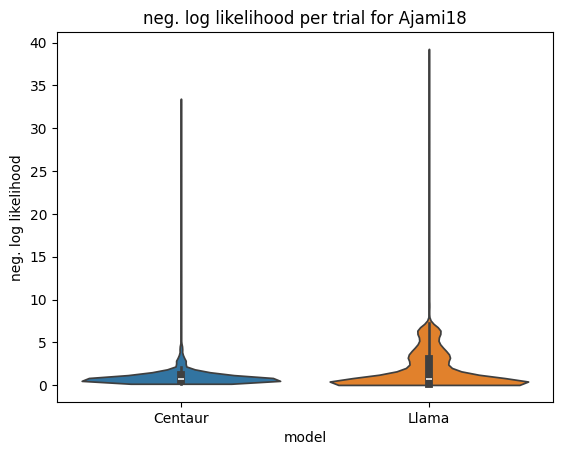

Bauer19: 88 Trials
Centaur mean: 4.3118365170423285, STD: 2.6205805067251218
Llama mean: 6.04525981851919, STD: 5.172294608892054
T-test statistic: -5.534767758527029, p-value: 3.2444878255911935e-07, cohen's d: -0.5900082254899495


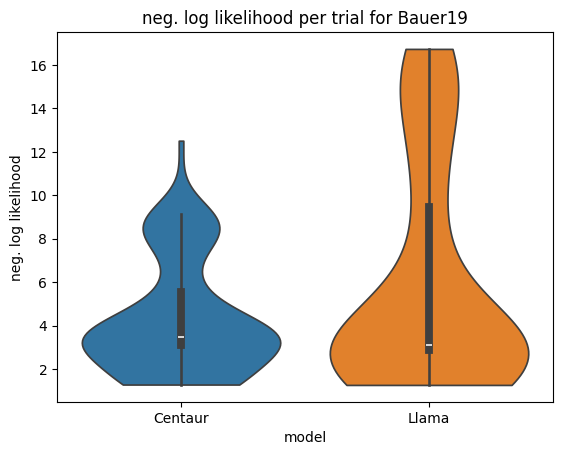

Börstler16: 2598 Trials
Centaur mean: 6.5541317771669485, STD: 6.7025866569667665
Llama mean: 7.051018235794735, STD: 7.391217071984628
T-test statistic: -10.187039440256836, p-value: 6.342266690060296e-24, cohen's d: -0.1998611648194376


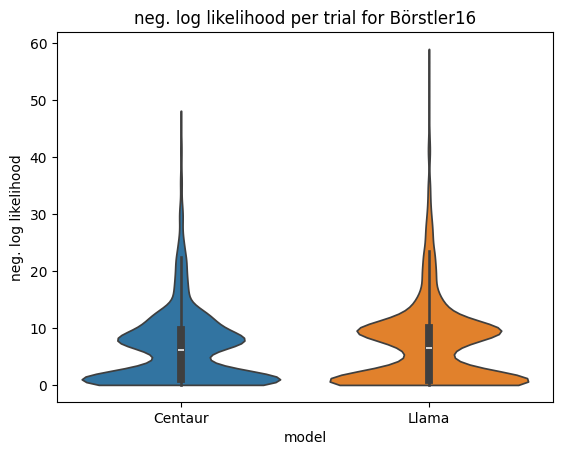

Buse10: 12100 Trials
Centaur mean: 4.2566345992822106, STD: 0.6969616984339588
Llama mean: 4.819222578642492, STD: 1.0571326980807811
T-test statistic: -73.06256355777151, p-value: 0.0, cohen's d: -0.6642051232524683


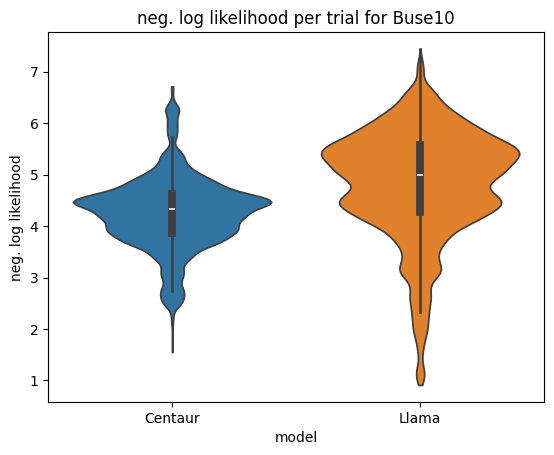

Gopstein17a: 6069 Trials
Centaur mean: 1.7639577355065805, STD: 3.198138353829743
Llama mean: 2.49530138878768, STD: 3.023415476325281
T-test statistic: -24.68974301377043, p-value: 2.481575244022309e-128, cohen's d: -0.3169260959372832


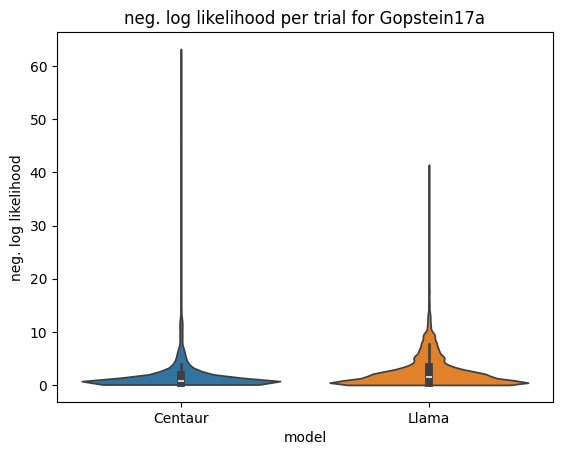

Gopstein17b: 498 Trials
Centaur mean: 4.84038336235278, STD: 3.9837027327830103
Llama mean: 5.644048129049404, STD: 4.244092943925958
T-test statistic: -7.74108572671822, p-value: 5.557660584972935e-14, cohen's d: -0.34688634594751694


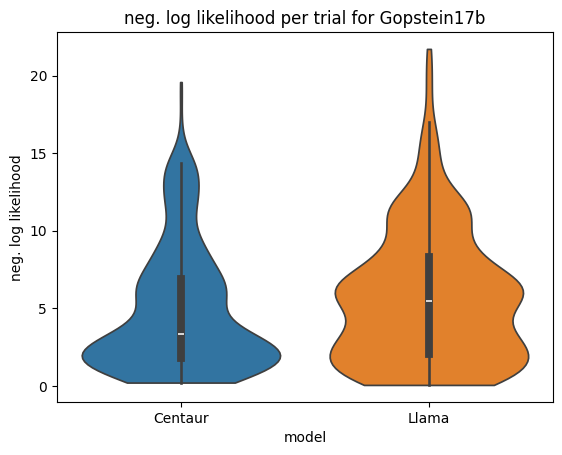

Medeiros19: 1164 Trials
Centaur mean: 3.3206548235267594, STD: 0.860708116856332
Llama mean: 3.835151881467373, STD: 1.1627568546926526
T-test statistic: -32.497814199574385, p-value: 2.30002400822412e-165, cohen's d: -0.9525278034157949


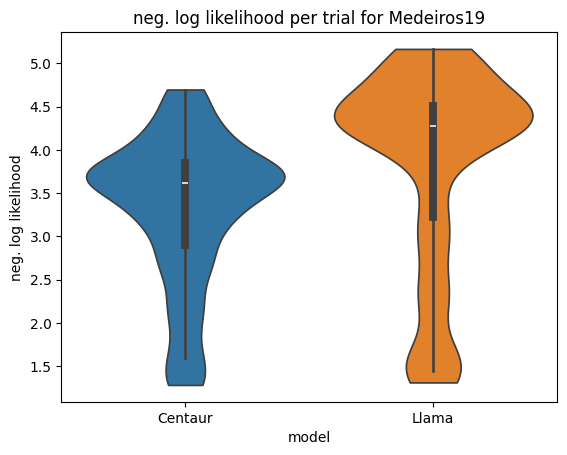

Peitek17: 420 Trials
Centaur mean: 7.257607832221765, STD: 1.2333989656688475
Llama mean: 9.421109116038114, STD: 0.7658345142317325
T-test statistic: -34.26033990654737, p-value: 1.442815588518128e-123, cohen's d: -1.6717334107020563


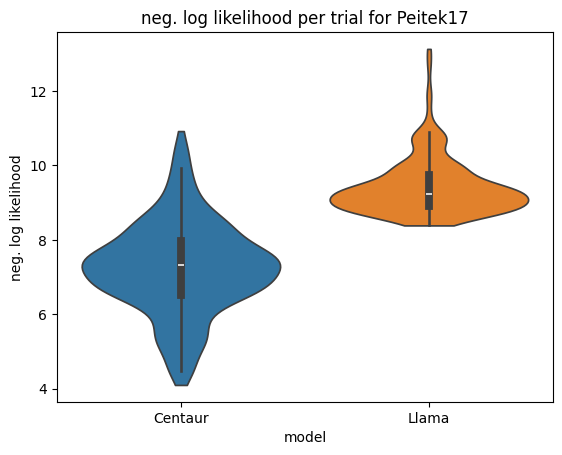

Peitek18b: 550 Trials
Centaur mean: 8.579571463301594, STD: 1.2146815608570443
Llama mean: 9.500699954476486, STD: 1.1225695912502547
T-test statistic: -14.84980750710852, p-value: 3.52488387024768e-42, cohen's d: -0.6331979196516916


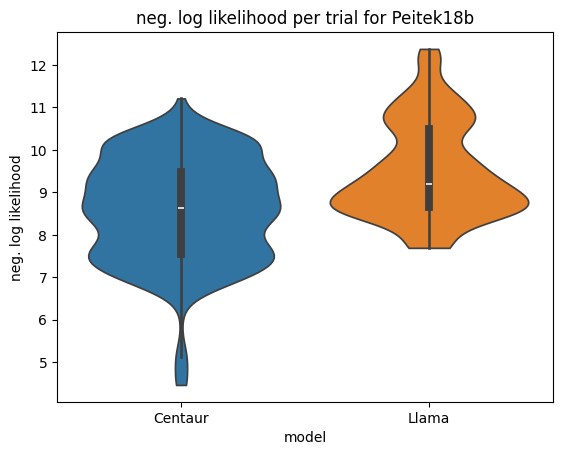

overall: 25554 Trials
Centaur mean: 3.7453988358307178, STD: 3.319662124840114
Llama mean: 4.396321330146857, STD: 3.533988979376437
T-test statistic: -62.011810452863116, p-value: 0.0, cohen's d: -0.38792249615242064


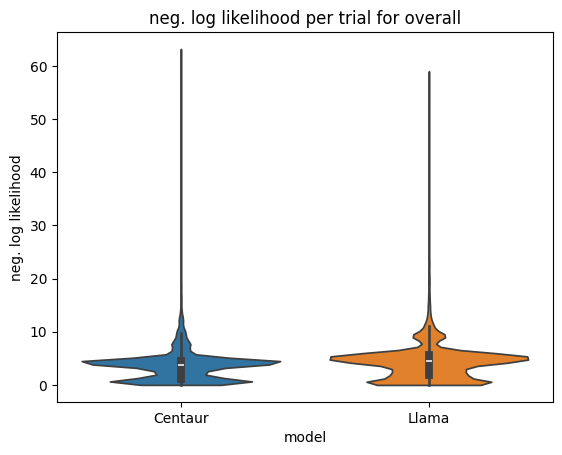

In [7]:
#TODO Violinplots & Eval
import seaborn as sns

import seaborn as sns
variant = "RQ2_no_order_no_desc"
for study in studies: 
    study_data_df = result_df[result_df["study"]==study]
    study_result_df = all_res_df[all_res_df["study"]==study]
    print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
    print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
    print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
    print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
    sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
    plt.ylabel("neg. log likelihood")
    plt.title(f"neg. log likelihood per trial for {study}")
    plt.savefig(f"images/{study}_violin_{variant}.png")
    plt.show()
    plt.close()
study = "overall"
study_data_df = result_df
study_result_df = all_res_df[all_res_df["study"]==study]
print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
plt.ylabel("neg. log likelihood")
plt.title(f"neg. log likelihood per trial for {study}")
plt.savefig(f"images/{study}_violin_{variant}.png")
plt.show()
plt.close()